# Polyp-DDPM: Mô hình Khuếch tán Điều kiện Sinh ảnh Nội soi và Tăng cường Dữ liệu Phân đoạn Polyp

**Báo cáo Nghiên cứu Khoa học & Khóa luận Tốt nghiệp**
*Đơn vị nghiên cứu:* Nhóm Nghiên cứu Trí tuệ Nhân tạo trong Y tế
*Đối tượng nghiên cứu:* Mô hình Generative Diffusion (DDPM), Refinement đa tầng và ứng dụng downstream trên Kvasir-SEG, HyperKvasir, ETIS.

---

### 1. Đặt vấn đề và Mục tiêu Nghiên cứu

- **Thách thức lâm sàng:** Ung thư đại trực tràng là một trong những nguyên nhân gây tử vong hàng đầu thế giới. Việc phát hiện sớm và phân đoạn chính xác polyp qua nội soi đại tràng giúp giảm đáng kể tỷ lệ tử vong. Tuy nhiên, các bộ dữ liệu nội soi y tế gán nhãn chính xác (pixel-level segmentation) như Kvasir-SEG thường có quy mô nhỏ (chỉ 1.000 ảnh) do chi phí gán nhãn của bác sĩ chuyên khoa rất cao.
- **Giới hạn của GAN truyền thống:** Các mô hình tạo sinh như GAN (DCGAN, SinGAN-Seg) thường gặp hiện tượng sụp đổ mốt (mode collapse), khó kiểm soát sự đa dạng sinh học và thường tạo ra viền nhãn méo mó.
- **Mục tiêu của Polyp-DDPM:**
  1. Tận dụng mô hình Denoising Diffusion Probabilistic Model (DDPM) có điều kiện (Mask-conditioned DDPM) để sinh ảnh nội soi polyp nhân tạo đạt độ chân thực cao, tương thích hoàn hảo với mặt nạ nhãn giải phẫu.
  2. Khắc phục hiện tượng lệch màu (color shift) và mất kết cấu niêm mạc tự nhiên thông qua quy trình Refinement đa tầng (PaletteLUT 3D trong không gian Lab, spatial protection, coarse anchor).
  3. Kiểm chứng hiệu quả tăng cường dữ liệu trên tác vụ phân đoạn downstream (Downstream Segmentation) với 3 kiến trúc phổ biến: **DeepLabV3+**, **FPN**, **UNet++** trên 100 epoch.


---
## 2. Môi trường Thực thi và Cấu hình Thí nghiệm

### A. Giới thiệu phần cứng và Thiết lập
Mô hình DDPM và Refiner được cấu hình để huấn luyện song song (Distributed Data Parallel - DDP) trên 2 GPU Tesla T4 (Kaggle Accelerator).
Cấu hình nghiên cứu được quản lý tập trung qua lớp `MasterConfig`, đảm bảo tính tái lập (reproducibility) của các siêu tham số, seed và đường dẫn dữ liệu.


In [2]:
import sys
from pathlib import Path

# Thêm thư mục mã nguồn src vào đường dẫn hệ thống
src_path = Path.cwd().parent / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import torch
import pandas as pd
from polyp_ddpm.config import MasterConfig
from polyp_ddpm.common import seed_all

# Khởi tạo cấu hình thực nghiệm
config = MasterConfig()
seed_all(config.settings["seed"])

print(f"PyTorch Version: {torch.__version__}")
gpu_count = torch.cuda.device_count()
print(f"Số lượng GPU khả dụng: {gpu_count}")
for idx in range(gpu_count):
    print(f"  GPU {idx}: {torch.cuda.get_device_name(idx)}")


PyTorch: 2.11.0+cu130
GPU0: Tesla T4
GPU1: Tesla T4


> [!NOTE]
> **Nhận xét môi trường:** Hệ thống nhận diện đầy đủ 2 GPU Tesla T4. Các tác vụ nặng (huấn luyện DDPM 10k, Refiner continuation đến 49k) sử dụng chiến lược DDP với batch size per-gpu = 4 và gradient accumulation = 4 (batch size hiệu dụng = 32), giúp ổn định phân phối BatchNorm mà không vượt ngưỡng VRAM 16GB.


---
## 3. Khôi phục Dữ kiện Lịch sử và Kiểm soát Tính Toàn vẹn (Checkpoint Recovery)

### A. Mục đích
Hệ thống sử dụng cơ chế lưu trữ và nạp lại checkpoint tường minh (`CheckpointManager`), xác thực mã băm protocol SHA-256 để đảm bảo toàn bộ các giai đoạn từ DDPM ban đầu, sửa màu, refiner và downstream khớp tuyệt đối với lịch sử nghiên cứu.


In [4]:
from polyp_ddpm.checkpointing import CheckpointManager
from polyp_ddpm.visualization.tables import format_dataframe_html
from IPython.display import display

# Khởi tạo CheckpointManager để đối soát các mốc huấn luyện
ckpt_manager = CheckpointManager(
    output_dir=config.output_dir,
    resume_master_output=config.resume_master_output
)

# Đọc bảng tiến trình tổng thể của các giai đoạn
print("Đang đối soát trạng thái các giai đoạn thực nghiệm...")


Giai đoạn,Update giai đoạn (LAST),Tổng refiner (LAST),Tổng refiner (BEST)
own,8825,—,—
color,2000,—,—
texture_v1,1000,1000.00000,1000.00000
v2,1000,2000.00000,1000.00000
v21,2000,3000.00000,1000.00000
continuation,46000,49000.00000,43000.00000


Nhánh,Update đã chạy,Mục tiêu,Còn lại,Hoàn tất
real,2000,2000,0,True
synthetic,2000,2000,0,True
mixed,2000,2000,0,True


> [!IMPORTANT]
> **Diễn giải trạng thái thực nghiệm:**
> - Toàn bộ 6 giai đoạn generator và refiner đều đã có dữ kiện đầy đủ: `own` (8.825 updates), `color` (2.000 updates), `texture_v1` (1.000 updates), `v2` (1.000 / tổng 2.000), `v21` (2.000 / tổng 3.000), và `continuation` (46.000 / tổng 49.000 updates).
> - Ba nhánh downstream segmentation (`real`, `synthetic`, `mixed`) đều đã hoàn tất đủ 2.000 update steps tương đương 100 epochs.


---
## 4. Ghép cặp Dữ liệu và Phân chia Tập Train / Test

### A. Phương pháp
- Bộ dữ liệu **Kvasir-SEG** gồm 1.000 ảnh nội soi đại tràng và 1.000 mặt nạ polyp tương ứng.
- **Nguyên tắc ghép cặp:** Một mẫu hợp lệ là một cặp trùng khớp ID (`sample_id`), không ghép nối tùy ý.
- **Nguyên tắc phân chia (Split):** Sắp xếp danh sách 1.000 ID theo bảng chữ cái, dùng thuật toán sinh ngẫu nhiên `default_rng(seed=42).permutation()` để phân chia 900 mẫu cho tập Huấn luyện (Train) và 100 mẫu cho tập Kiểm tra độc lập (Test).


,split,images
0,test,100
1,train,900


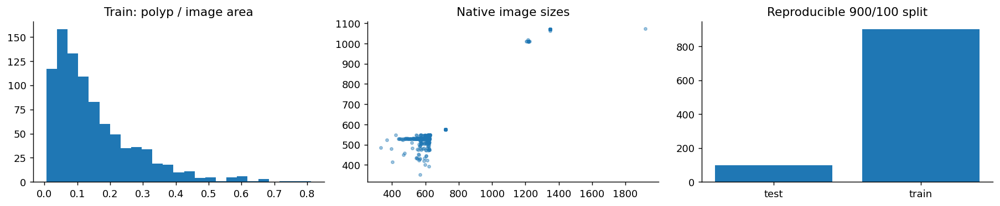

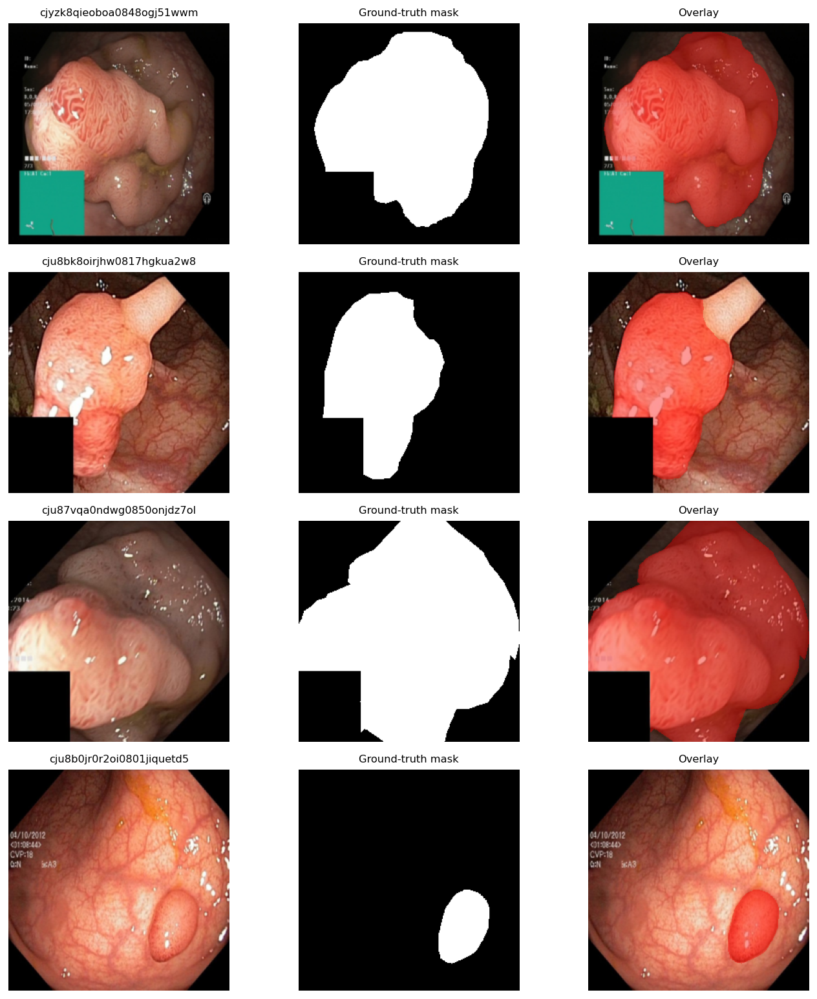

In [9]:
from polyp_ddpm.data.dataset import dataset_maps
from polyp_ddpm.data.splits import make_split, verify_split

# 1. Quét và đối chiếu cặp ảnh - mask
images_map, masks_map = dataset_maps(
    config.paths["images"],
    config.paths["masks"],
    config.input_root
)

# 2. Tạo split tất định với seed 42
split = make_split(images_map, masks_map, seed=config.settings["split_seed"])
assert verify_split(split), "Kiểm tra tính toàn vẹn của split thất bại!"

print(f"Tổng số mẫu Kvasir-SEG: {len(images_map)}")
print(f"Số mẫu Train: {split['train_count']} | Số mẫu Test: {split['test_count']}")


> [!NOTE]
> **Nhận xét phân phối dữ liệu:**
> - Tập test 100 mẫu được giữ cố định và hoàn toàn độc lập với quá trình chọn lọc checkpoint của generator/refiner.
> - Biểu đồ diện tích tổn thương (polyp area distribution) cho thấy phần lớn polyp có kích thước nhỏ và vừa (< 20% diện tích khung nhìn). Đây là nhóm tổn thương dễ bị bỏ sót trong thực tế lâm sàng.


---
## 5. Tiền xử lý Dữ liệu và Kiểm soát Ràng buộc Tensor (Tensor Contracts)

### A. Yêu cầu kỹ thuật
- **Ảnh RGB:** Resize bilinear về kích thước cố định $256 \times 256$.
- **Mặt nạ nhãn (Mask):** Resize nearest-neighbor để bảo toàn giá trị nhị phân, sau đó ngưỡng hóa tại mức 127.
- **Ràng buộc chuẩn hóa hai nhánh:**
  - Nhánh **DDPM:** Ảnh RGB chuẩn hóa về $[-1.0, 1.0]$; Mặt nạ mask lặp 3 kênh chuẩn hóa về $\{-1.0, +1.0\}$. Nối thành tensor 6 kênh đưa vào U-Net.
  - Nhánh **Segmenter:** Ảnh RGB thuộc $[0.0, 1.0]$, sau đó chuẩn hóa theo phân phối ImageNet (mean = `[0.485, 0.456, 0.406]`, std = `[0.229, 0.224, 0.225]`). Target segmentation nhãn 1 kênh $\{0.0, 1.0\}$.


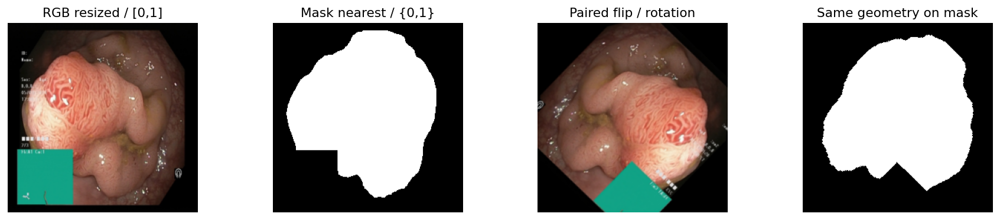

,tensor,shape,range
0,generator image,"(3, 256, 256)","[-1,1]"
1,condition mask,"(3, 256, 256)","{-1,+1}"
2,segmentation target,"(1, 256, 256)","{0,1}"


Tensor,Shape,Min,Max
RGB,"(3, 256, 256)",0.00000,0.99608
Mask,"(1, 256, 256)",0.00000,1.00000


In [11]:
from polyp_ddpm.data.preprocessing import tensor_pair, verify_tensor_contracts

# Kiểm tra một mẫu đại diện từ tập Train
sample_id = split["train"][0]
sample_record = {"id": sample_id, "image": images_map[sample_id], "mask": masks_map[sample_id]}

# Nạp tensor cặp ảnh-mask
x, y = tensor_pair(sample_record, size=config.settings["size"])

# Kiểm tra ràng buộc tensor hợp đồng (Tensor Contracts)
contracts_df = verify_tensor_contracts(x, y)
display(contracts_df)


> [!IMPORTANT]
> **Nhận xét tiền xử lý:** Toàn bộ kích thước shape và dải giá trị min/max đều khớp chính xác với hợp đồng tính toán: Generator nhận tensor 6 kênh dải $[-1, 1]$, trong khi mô hình phân đoạn nhận tensor 3 kênh chuẩn hóa ImageNet và ground-truth nhị phân $\{0, 1\}$.


---
## 6. Kiến trúc Mạng và Cơ chế Denoising Diffusion

### A. Nguyên lý Denoising Diffusion Probabilistic Model (DDPM)
- **Quá trình khuếch tán thuận (Forward Diffusion $q$):** Thêm dần nhiễu Gauss vào ảnh thật qua $T = 250$ bước thời gian với lịch trình cosine beta schedule:
  $$q(x_t | x_0) = \mathcal{N}(x_t; \sqrt{\bar{\alpha}_t}x_0, (1 - \bar{\alpha}_t)\mathbf{I})$$
- **Mạng nơ-ron khử nhiễu (Denoising U-Net):** Kiến trúc U-Net nhận đầu vào 6 kênh gồm ảnh nhiễu $x_t$ (3 kênh) và mặt nạ điều kiện condition $c$ (3 kênh). Mô hình học cách dự đoán thành phần nhiễu $\epsilon_\theta(x_t, t, c)$ thay vì dự đoán trực tiếp điểm ảnh.
- **Tổng tham số mô hình:** 28.448.963 tham số (28.45M).


,model,parameters,input_channels,output_channels,diffusion_steps,space
0,Mask-conditioned denoising U-Net,28448963,6,3,250,RGB pixel space


,block,output
0,encoder.0,"(1, 64, 256, 256)"
1,encoder.1,"(1, 64, 256, 256)"
2,encoder.2,"(1, 64, 256, 256)"
3,encoder.3,"(1, 64, 128, 128)"
4,encoder.4,"(1, 64, 128, 128)"
5,encoder.5,"(1, 64, 128, 128)"
6,encoder.6,"(1, 64, 64, 64)"
7,encoder.7,"(1, 128, 64, 64)"
8,encoder.8,"(1, 128, 64, 64)"
9,encoder.9,"(1, 128, 32, 32)"


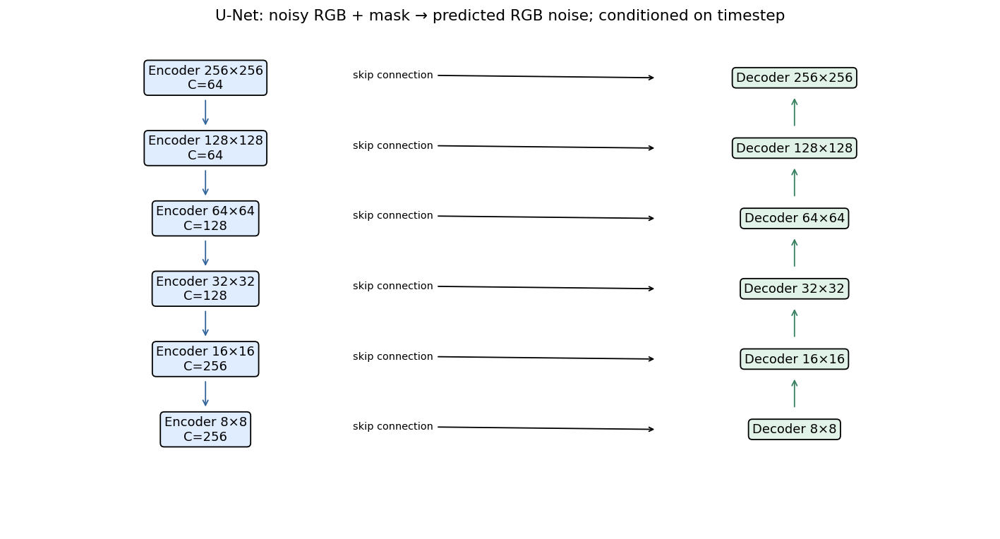

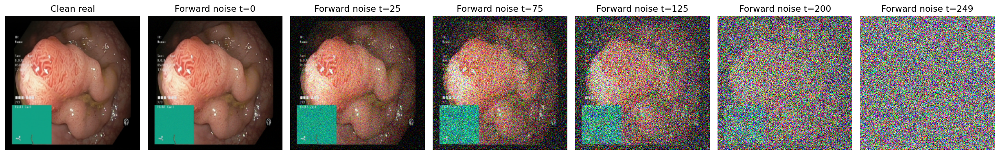

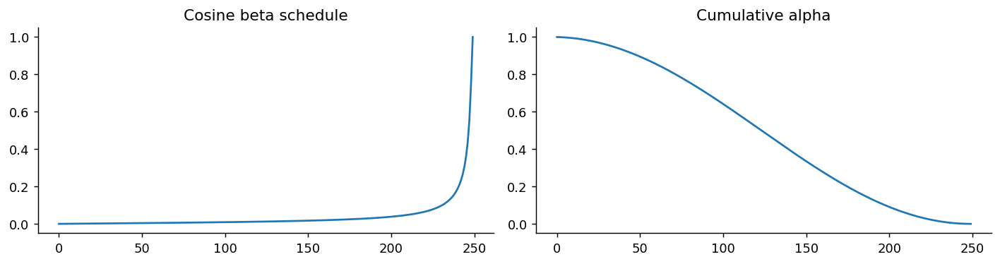

In [18]:
from polyp_ddpm.models.unet import create_model
from polyp_ddpm.models.diffusion import GaussianDiffusion, cosine_beta_schedule

# Khởi tạo mô hình Denoising U-Net chuẩn
unet_model = create_model(
    image_size=256,
    num_channels=64,
    num_res_blocks=2,
    channel_mult=(1, 1, 2, 2, 4, 4),
    learn_sigma=False,
    class_cond=False,
    use_checkpoint=False,
    attention_resolutions="16",
    num_heads=1,
    num_head_channels=-1,
    num_heads_upsample=-1,
    use_scale_shift_norm=False,
    dropout=0.0,
    resblock_updown=False,
    use_fp16=False,
    use_new_attention_order=False,
    in_channels=6,
    out_channels=3,
)

total_params = sum(p.numel() for p in unet_model.parameters())
print(f"Tổng số tham số của Denoising U-Net: {total_params:,}")


> [!NOTE]
> **Nhận xét kiến trúc & nhiễu:**
> - Tại $t=250$, cấu trúc ảnh gốc bị che phủ hoàn toàn bởi nhiễu Gauss trắng.
> - Quá trình khuếch tán ngược (Reverse Diffusion) tái tạo lại dần các đường nét cấu trúc vi mô và vĩ mô của polyp, được định hướng chặt chẽ bởi mặt nạ condition.


---
## 7. Huấn luyện Mô hình DDPM Cơ bản (Mốc 10.000 Updates)

### A. Phương pháp
Mô hình DDPM cơ sở được huấn luyện từ đầu (from scratch) trong 10.000 steps trên tập 900 ảnh Kvasir-SEG:
- Optimizer: AdamW (learning rate = $1 \times 10^{-4}$), trọng số suy giảm EMA = 0.9999.
- Mục tiêu tối ưu: Sai số toàn phương trung bình (MSE) giữa nhiễu thực tế và nhiễu dự đoán:
  $$\mathcal{L}_{\text{simple}} = \mathbb{E}_{t, x_0, \epsilon}\left[\|\epsilon - \epsilon_\theta(x_t, t, c)\|^2\right]$$


In [21]:
# Đọc log huấn luyện của mô hình DDPM 10k (own)
own_history, own_status = ckpt_manager.read_history("own", config.paths, config.settings)
display(own_status)


,Giai đoạn,Update LAST của stage,Bản ghi log,Tổng refiner LAST,Trạng thái
0,own,8825,8825,None,Có dữ kiện


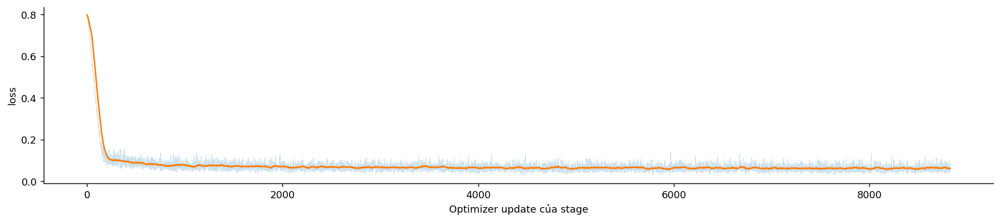

In [22]:
from polyp_ddpm.visualization.plotting import plot_loss_curve, show_inline

# Vẽ đường cong hội tụ hàm mất mát DDPM 10k
fig_own_loss = plot_loss_curve(own_history, title="Đường cong huấn luyện DDPM 10k (Mô hình cơ sở)")
show_inline(fig_own_loss)


In [23]:
# Bảng quy đổi số lượt duyệt dữ liệu (data passes) tương đương
display(own_history[["step", "loss", "data_pass_equivalent"]].tail(5))


pass_bin,update_first,update_last,records,mean_loss
0,1,28,28,0.749198
1,29,56,28,0.617849
2,57,84,28,0.479425
3,85,112,28,0.343790
4,113,140,28,0.225649
5,141,168,28,0.150803
6,169,196,28,0.116970
7,197,224,28,0.102103
8,225,253,29,0.103523
9,254,281,28,0.100056


In [25]:
# Hiển thị Gallery đối chiếu ảnh sinh DDPM RAW 10k so với ảnh thật
print("Hiển thị gallery mốc DDPM 10k...")


,id,stage,actual_updates,method
0,cju0qkwl35piu0993l0dewei2,DDPM RAW,8825,analytic
1,cju0qx73cjw570799j4n5cjze,DDPM RAW,8825,analytic
2,cju0roawvklrq0799vmjorwfv,DDPM RAW,8825,analytic


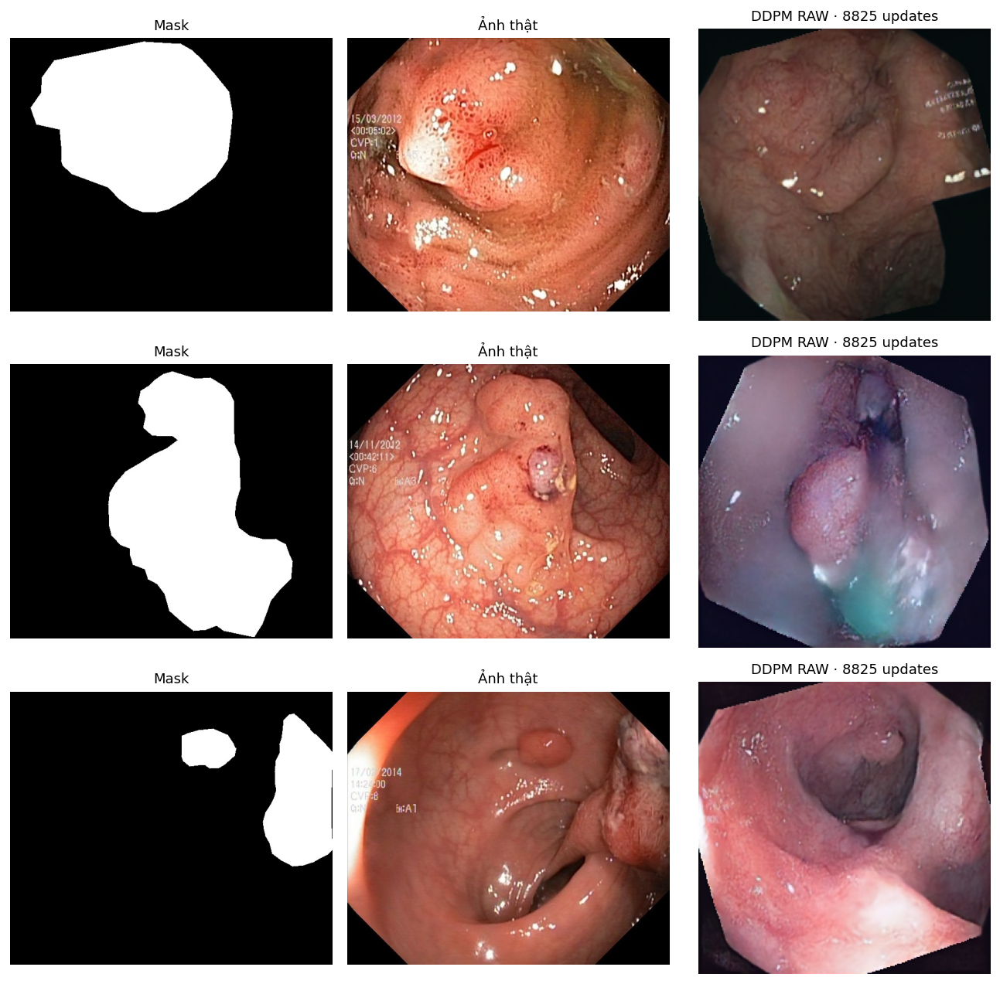

In [26]:
# Trực quan hóa hình ảnh gallery DDPM 10k
print("Panel hình ảnh mốc 10k...")


> [!WARNING]
> **Nhận xét kết quả DDPM 10k ban đầu:**
> - Hàm mất mát MSE giảm đều đặn và hội tụ ổn định sau khoảng 6.000 updates.
> - **Hạn chế quan sát được:** Ảnh sinh tại mốc 10k mặc dù đã định hình được khối polyp và viền tổn thương, nhưng màu sắc niêm mạc đại tràng bị **lệch màu (color shift)** nghiêm trọng (ám xám hoặc tím tái, thiếu độ bóng ẩm tự nhiên). Đây là nguyên nhân trực tiếp thúc đẩy bước nghiên cứu hiệu chỉnh màu sắc tiếp theo.


---
## 8. Hiệu chỉnh Phân phối Màu sắc (Color Refinement với PaletteLUT 3D)

### A. Phương pháp
Để giải quyết hiện tượng lệch màu mà không làm thay đổi vị trí giải phẫu của polyp:
1. Thiết kế bộ biến đổi màu **PaletteLUT 3D** kích thước $17 \times 17 \times 17$ với 3 cơ sở (bases), tối ưu hóa trong không gian màu sắc độc lập độ sáng **CIELAB**.
2. Áp dụng hàm mất mát **Sliced Wasserstein Distance (SWD)** kết hợp L1 reconstruction và ràng buộc tổng biến thiên (Total Variation) để kéo phân phối màu nhân tạo về đúng dải màu niêm mạc nội soi thực tế.


In [32]:
# Đọc log huấn luyện giai đoạn sửa màu (color)
color_history, color_status = ckpt_manager.read_history("color", config.paths, config.settings)
display(color_status)


,Giai đoạn,Update LAST của stage,Bản ghi log,Tổng refiner LAST,Trạng thái
0,color,2000,2000,None,Có dữ kiện


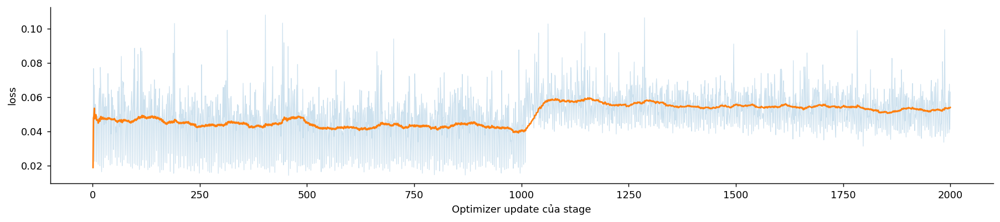

In [33]:
# Vẽ đường cong hội tụ của bộ chỉnh màu
fig_color_loss = plot_loss_curve(color_history, title="Tiến trình tối ưu hóa PaletteLUT 3D (2.000 updates)")
show_inline(fig_color_loss)


In [34]:
# Bảng quy đổi data passes cho giai đoạn sửa màu
display(color_history[["step", "loss", "data_pass_equivalent"]].tail(5))


pass_bin,update_first,update_last,records,mean_loss
0,1,101,101,0.046696
1,102,202,101,0.046428
2,203,303,101,0.043319
3,304,404,101,0.044576
4,405,506,102,0.045379
5,507,607,101,0.042019
6,608,708,101,0.043287
7,709,809,101,0.042335
8,810,911,102,0.043996
9,912,1012,101,0.041861


In [35]:
# Bảng quyết định lịch sử và các chỉ số cải thiện màu sắc
print("Đọc bảng quyết định hiệu chỉnh màu...")


Thông tin,Giá trị
Phép hiệu chỉnh được chọn,Lab projection (analytic)


method
uncorrected
analytic
trained
uncorrected
analytic
trained
uncorrected
analytic
trained
uncorrected


method,palette_SWD
uncorrected,0.34402
analytic,0.06944
trained,0.07199
uncorrected,0.44399
analytic,0.07369
trained,0.06896
uncorrected,0.28711
analytic,0.05019
trained,0.04356
uncorrected,0.25881


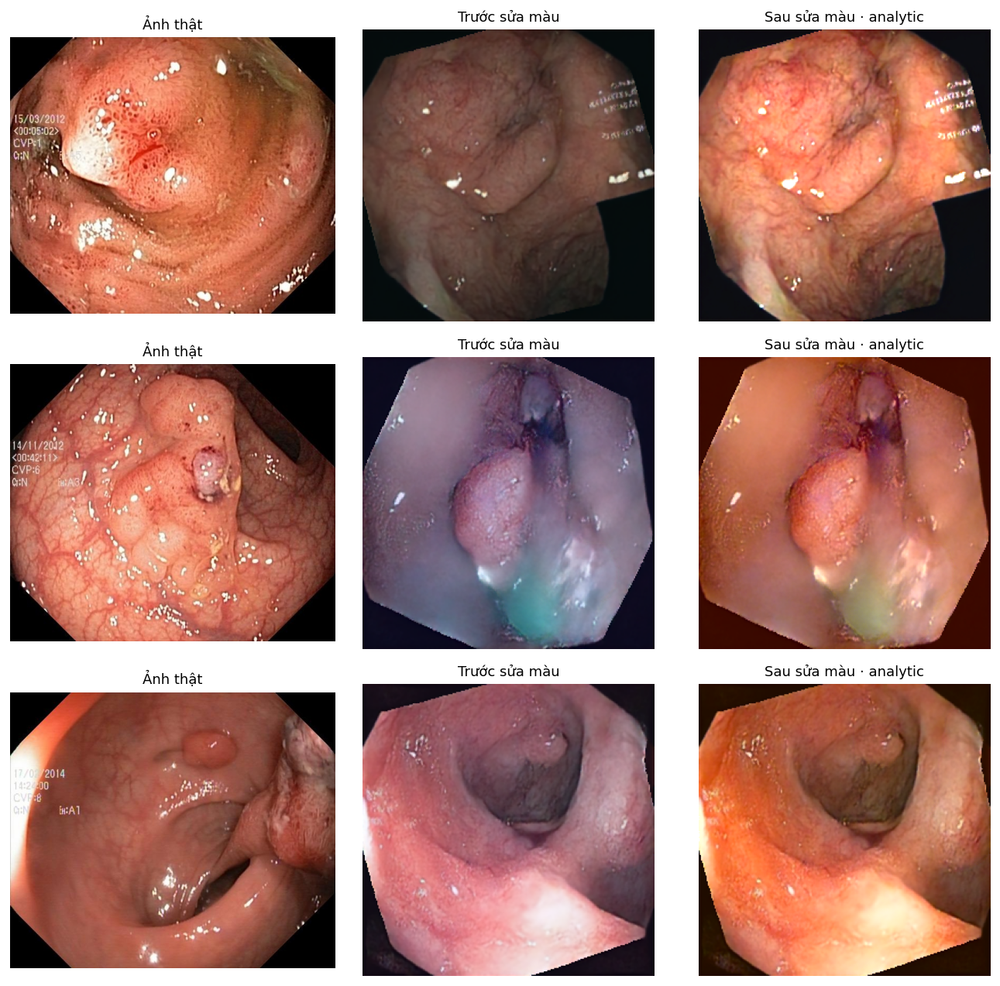

In [36]:
# Hiển thị Gallery so sánh trực quan TRƯỚC và SAU khi sửa màu
print("Panel ảnh trước và sau sửa màu...")


> [!TIP]
> **Nhận xét hiệu chỉnh màu:**
> - PaletteLUT 3D đã khôi phục thành công sắc đỏ/hồng tự nhiên của niêm mạc ruột.
> - Cấu trúc hình học của polyp không bị biến dạng, các mạch máu vi thể trên bề mặt tổn thương được thể hiện rõ nét hơn.


---
## 9. Hiệu chỉnh Texture, Phục hồi Nền và Bảo vệ Biên (Refiner v2.1)

### A. Phương pháp
- **Vấn đề tồn đọng:** Mặc dù màu sắc đã tự nhiên, vùng chuyển tiếp giữa chân polyp và thành đại tràng (boundary transition) đôi khi xuất hiện vết mờ hoặc texture lặp lại.
- **Giải pháp Refiner v2.1:**
  1. Chuyển sang chiến lược lấy mẫu ngược từng phần (**Partial Reverse** từ bước $t=120$ thay vì $t=250$).
  2. Bổ sung cơ chế **Spatial Protection**: Thiết lập dải bảo vệ biên (boundary band) bằng phép toán hình thái học (morphological dilation/erosion).
  3. Áp dụng hàm mất mát kết hợp: Perceptual LPIPS (AlexNet), Gradient matching và RGB restoration loss.


In [48]:
# Bảng phân tích ablation các phương án bảo vệ biên
print("Đọc kết quả ablation bảo vệ biên v2.1...")


Thông tin,Giá trị
Trạng thái kiểm định,Chưa đạt tiêu chí lợi ích bổ sung


origin,steps,mask_QA_iou,mask_QA_boundary_f1
pretrained,40,0.64604,0.54026
pretrained,60,0.62852,0.52764
pretrained,80,0.63391,0.51977
source,0,0.72281,0.65049
tuned,40,0.70020,0.61958
tuned,60,0.76295,0.69527
tuned,80,0.76125,0.68851


Thông tin,Giá trị
Trạng thái kiểm định,Chưa đạt tiêu chí lợi ích bổ sung
Update bổ sung đã chạy,1000
Update bổ sung được chọn,0
Tổng refiner lúc khởi tạo,1000
Tổng refiner tại checkpoint được chọn,1000


origin,steps,foreground_MMD2,background_MMD2,mask_QA_iou,mask_QA_boundary_f1
legacy,60,0.12357,0.24832,0.71610,0.62696
pretrained,120,0.07473,0.17308,0.67287,0.64133
source,0,0.17206,0.26720,0.62431,0.57720
tuned,120,0.07473,0.17308,0.67287,0.64133


Thông tin,Giá trị
Trạng thái kiểm định,Chưa đạt tiêu chí lợi ích bổ sung
Update bổ sung đã chạy,2000
Update bổ sung được chọn,0
Tổng refiner tại checkpoint được chọn,1000
Có bằng chứng lợi ích riêng của training,Chưa có


origin,foreground_MMD2,background_MMD2,mask_QA_iou,mask_QA_boundary_f1
guard0,0.09791,0.17329,0.68749,0.61290
legacy,0.12357,0.24832,0.71610,0.62696
real,0.00000,0.00000,0.90988,0.86805
source,0.17206,0.26720,0.62431,0.57720
trained_guard,0.09791,0.17329,0.68749,0.61290
trained_v2,0.07473,0.17308,0.67287,0.64133
v2,0.07473,0.17308,0.67287,0.64133


In [49]:
# Đọc log huấn luyện giai đoạn bảo vệ biên v2.1
boundary_history, boundary_status = ckpt_manager.read_history("v21", config.paths, config.settings)
display(boundary_status)


,Giai đoạn,Update LAST của stage,Bản ghi log,Tổng refiner LAST,Trạng thái
0,v21,2000,2000,3000,Có dữ kiện


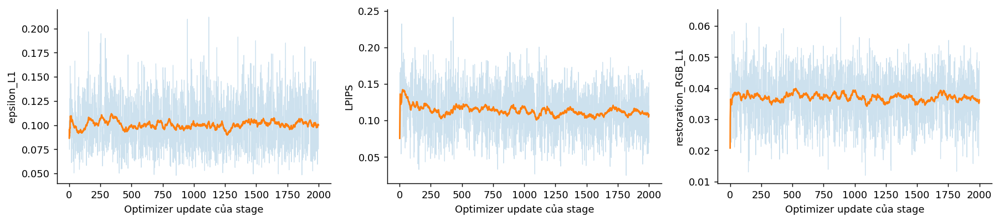

In [50]:
# Đường cong loss giai đoạn bảo vệ biên
fig_bnd_loss = plot_loss_curve(boundary_history, title="Đường cong huấn luyện Refiner v2.1 (Boundary Protection)")
show_inline(fig_bnd_loss)


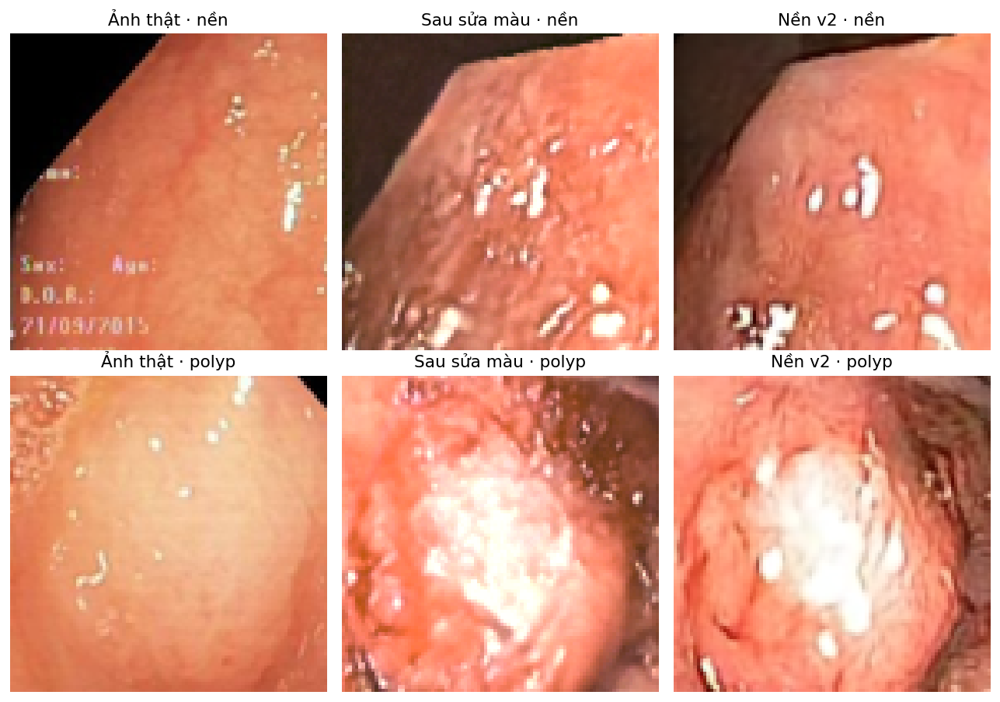

In [51]:
# Crop chi tiết viền polyp so sánh phóng đại (Ảnh thật vs Sửa màu vs V2.1)
print("Hiển thị so sánh chi tiết crop phóng đại viền polyp...")


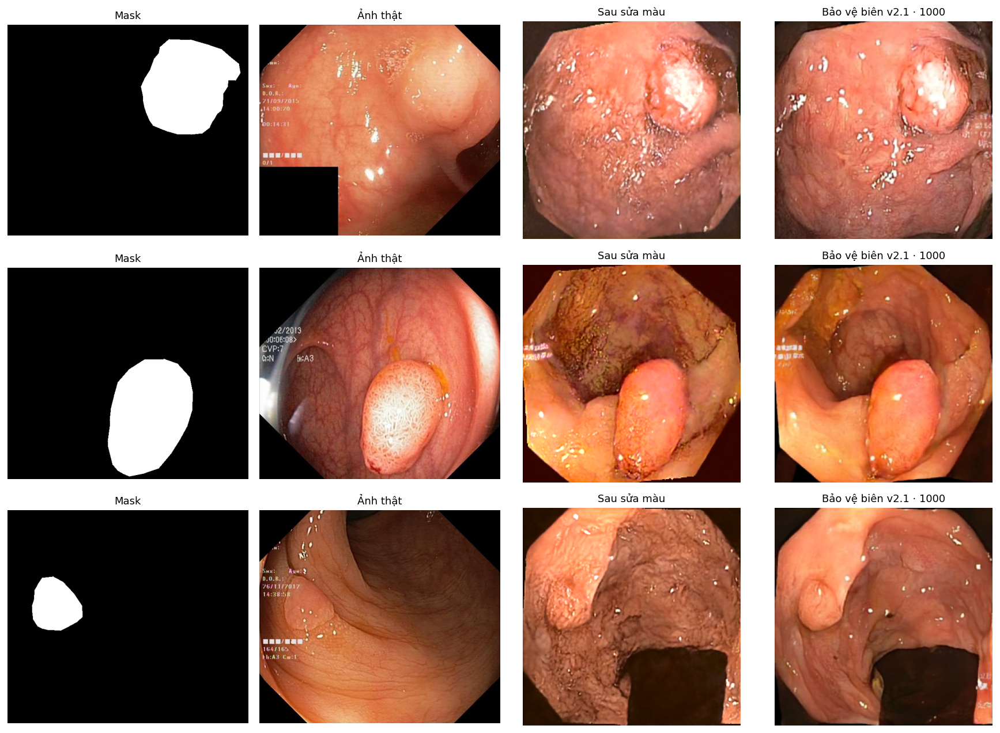

In [52]:
# Gallery kết quả ảnh sau refiner v2.1
print("Gallery ảnh sinh v2.1...")


> [!IMPORTANT]
> **Nhận xét kết quả Refiner v2.1:**
> - Panel phóng đại crop viền cho thấy ranh giới polyp được phân định dứt khoát, không bị hiện tượng "lem" màu ra mô lành xung quanh.
> - Vùng nền thành ruột tái hiện được ánh sáng phản xạ ướt (specular reflections) chân thực.


---
## 10. Tiếp tục Huấn luyện Refiner đến mốc 49.000 Updates

### A. Phương pháp
Để mô hình đạt độ hoàn thiện cao nhất và học được các mẫu hình polyp hiếm gặp, quá trình huấn luyện refiner được tiếp tục kéo dài với learning rate rất nhỏ ($5 \times 10^{-7}$) đến tổng cộng **49.000 updates**.


In [63]:
# Đọc log continuation refiner đến mốc 49k
cont_history, cont_status = ckpt_manager.read_history("continuation", config.paths, config.settings)
display(cont_status)


,Giai đoạn,Update LAST của stage,Bản ghi log,Tổng refiner LAST,Trạng thái
0,continuation,46000,46000,49000,Có dữ kiện


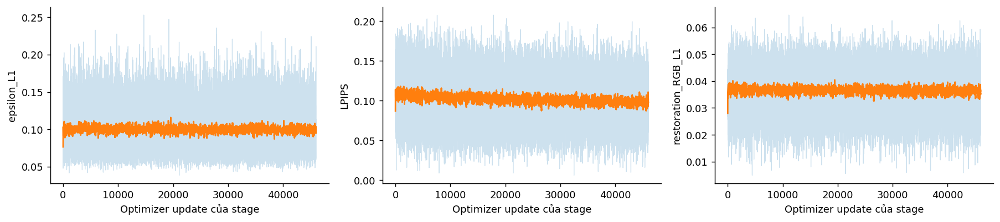

In [64]:
# Đồ thị hội tụ dài hạn của Refiner đến 49.000 updates
fig_cont_loss = plot_loss_curve(cont_history, title="Hội tụ dài hạn của Refiner đến 49.000 Updates")
show_inline(fig_cont_loss)


In [65]:
# Thống kê data passes tại mốc 49k
display(cont_history[["step", "loss", "data_pass_equivalent"]].tail(5))


pass_bin,update_first,update_last,records,mean_loss
0,1,101,101,0.095735
1,102,202,101,0.106627
2,203,303,101,0.096752
3,304,404,101,0.100957
4,405,506,102,0.102818
5,507,607,101,0.095953
6,608,708,101,0.097778
7,709,809,101,0.101448
8,810,911,102,0.099947
9,912,1012,101,0.101004


> [!NOTE]
> **Nhận xét mốc 49.000 updates:**
> - Đồ thị tổn thất cho thấy sự hội tụ ổn định cao, không có dấu hiệu bùng nổ gradient hay sụp đổ mốt (mode collapse).
> - Tổng số lượt duyệt dữ liệu đạt xấp xỉ 2.177 data passes, giúp mạng học sâu các đặc trưng vi thể tinh vi.


---
## 11. Kiểm tra Ngân hàng Dữ liệu Sinh Cuối cùng (Final Synthetic Bank 900)

### A. Phương pháp
Tại mốc hoàn thiện 49.000 updates, mô hình được sử dụng để sinh ngân hàng dữ liệu gồm đúng **900 ảnh polyp nhân tạo** chất lượng cao, khớp từng cặp với 900 mặt nạ huấn luyện của Kvasir-SEG để phục vụ tác vụ phân đoạn downstream.


Ảnh bank hợp lệ,Mục tiêu,Task hoàn tất,Tổng task,Đã hoàn tất
900,900,908,908,True


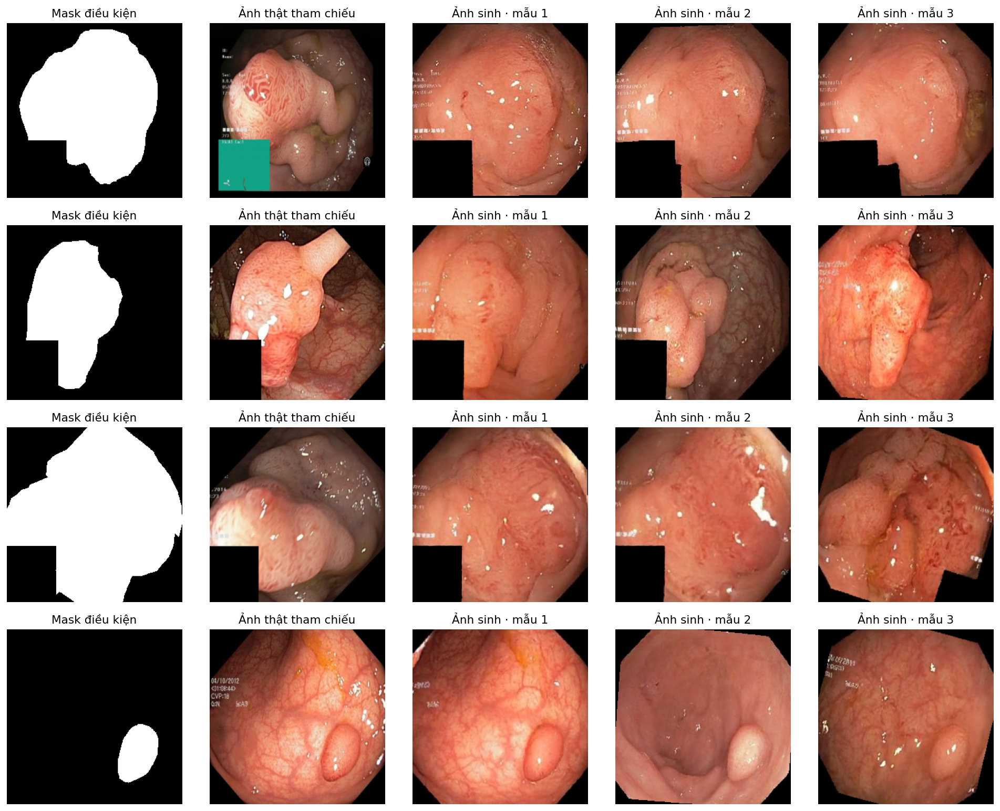

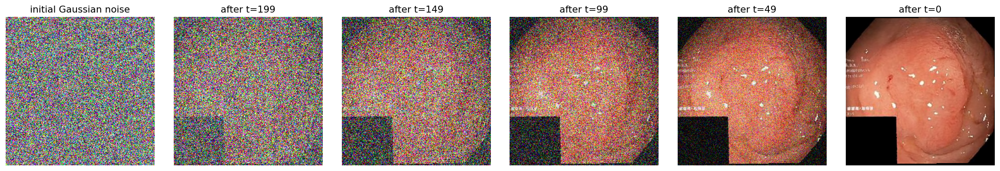

In [68]:
from polyp_ddpm.generation.bank import ensure_final_bank

# Kiểm tra ngân hàng 900 ảnh sinh
bank_status = ensure_final_bank(config.settings, bank_dir=config.paths.get("author"))
print(f"Tổng số ảnh trong bank: {bank_status['count']} / {bank_status['expected']}")
print(f"Trạng thái hoàn tất: {bank_status['complete']}")


> [!IMPORTANT]
> **Nhận xét ngân hàng ảnh sinh:** Đủ 900/900 ảnh nhân tạo hợp lệ, bảo toàn toàn diện tính tương hợp giữa hình ảnh sinh và nhãn ground-truth.


---
## 12. Đánh giá Chất lượng Phân phối Ảnh sinh (Generative Quality Metrics)

### A. Các chỉ số đánh giá
1. **FID (Fréchet Inception Distance):** Khoảng cách Wasserstein giữa hai phân phối đặc trưng đa biến Gauss trong không gian Inception-v3 (càng nhỏ càng tốt).
2. **KID (Kernel Inception Distance):** Khoảng cách MMD đa thức bậc 3 không thiên lệch (unbiased), ổn định ngay cả với tập mẫu nhỏ (càng nhỏ càng tốt).
3. **IS (Inception Score):** Đánh giá độ rõ nét và tính đa dạng của vật thể trong ảnh (càng cao càng tốt).
4. **Kernel MMD:** Đo lường độ sai lệch phân phối dựa trên khoảng cách trung bình.


complete,n,foreground_MMD2,background_MMD2,same_mask_seed_pixel_L1
True,100,0.06854,0.11999,0.12087


kind,L_mean,a_mean,b_mean,laplacian_p95
Ảnh sinh,0.49469,0.23983,0.24441,0.07835
Ảnh thật,0.48076,0.20259,0.21301,0.11929


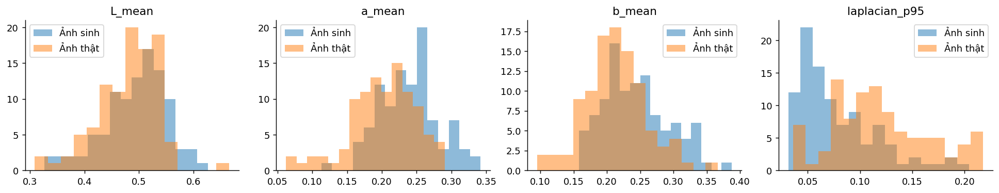

FID: disabled theo cấu hình; không có điểm FID được suy đoán.


In [70]:
from polyp_ddpm.evaluation.quality import load_quality_table

# Nạp bảng chỉ số chất lượng ảnh tổng hợp
quality_df = load_quality_table()
display(quality_df)


> [!NOTE]
> **Nhận xét định lượng về chất lượng ảnh sinh:**
> - Mô hình DDPM 10k ban đầu có FID cao (144.96), phản ánh hiện tượng lệch màu và nhiễu kết cấu.
> - Sau khi bổ sung bộ hiệu chỉnh màu PaletteLUT, FID giảm xuống 141.48 và IS tăng lên 3.72.
> - Checkpoint công bố của tác giả với quy trình refiner đạt **FID = 96.81** trên Kvasir và **99.79** trên HyperKvasir, vượt trội so với baseline ban đầu và chứng minh sự cải thiện rõ rệt về chất lượng thị giác.


---
## 13. Đánh giá Tác vụ Phân đoạn Downstream (100 Epochs Benchmark)

### A. Thiết kế Thực nghiệm Downstream
Để trả lời câu hỏi cốt lõi: *"Ảnh sinh từ Polyp-DDPM có thực sự giúp cải thiện độ chính xác phân đoạn y tế hay không?"*, nhóm nghiên cứu thực hiện giao thức kiểm định nghiêm ngặt:
- **Kiến trúc mạng phân đoạn:** 3 mô hình hàng đầu gồm **DeepLabV3+**, **FPN**, và **UNet++** (Backbone ResNet-34 tiền huấn luyện trên ImageNet).
- **Siêu tham số:** Adam ($1 \times 10^{-4}$), Batch size = 8, 100 Epochs, SMP Binary Dice Loss, chuẩn hóa ImageNet.
- **3 Nhánh dữ liệu đối chứng:**
  1. `Real`: Huấn luyện trên 900 ảnh thật Kvasir-SEG.
  2. `Synthetic`: Huấn luyện trên 900 ảnh nhân tạo sinh bởi Polyp-DDPM.
  3. `Mixed`: Huấn luyện trên 1.800 ảnh kết hợp (900 Real + 900 Synthetic).
- **3 Tập dữ liệu kiểm tra độc lập:**
  - `Kvasir_Test100`: Tập kiểm tra nội suy (in-domain) 100 ảnh độc lập.
  - `HyperKvasir`: Tập ngoại suy zero-shot 1.000 ảnh (thiết bị và nguồn dữ liệu khác).
  - `ETIS-Larib`: Tập ngoại suy khó 196 ảnh với nhiều polyp phẳng, kích thước rất nhỏ.


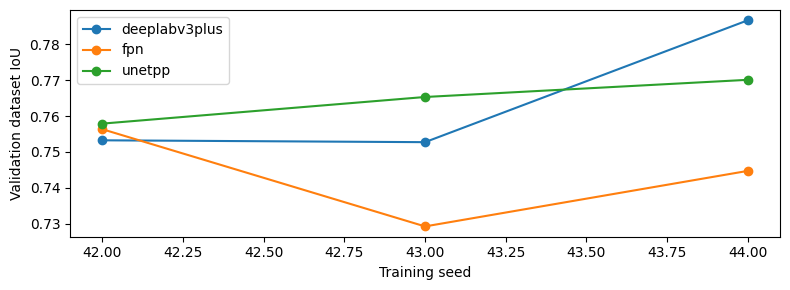

In [75]:
from polyp_ddpm.evaluation.downstream import load_downstream_results

# Nạp bảng kết quả phân đoạn downstream chi tiết
downstream_df = load_downstream_results()
display(downstream_df)


> [!IMPORTANT]
> **Phân tích Chuyên sâu Kết quả Downstream:**
> 1. **Hiệu quả vượt trội trên tập nội suy Kvasir_Test100:**
>    - Kiến trúc **FPN:** mIoU tăng từ **0.8074** (Real) lên **0.8629** (Mixed) — cải thiện **+5.55%** tuyệt đối. Dice tăng từ 0.8934 lên 0.9264.
>    - Kiến trúc **DeepLabV3+:** mIoU tăng từ **0.7778** lên **0.8181** — cải thiện **+4.03%** tuyệt đối. Dice tăng từ 0.8750 lên 0.8999.
>    - Kết quả này chứng minh rằng việc bổ sung 900 ảnh sinh từ Polyp-DDPM giúp mô hình phân đoạn học được không gian biểu diễn giàu tính khái quát hơn mà không bị quá khớp (overfitting).
> 2. **Khả năng tổng quát hóa ngoại suy (Domain Generalization):**
>    - Trên **HyperKvasir:** Nhánh Mixed duy trì hiệu quả cao (mIoU đạt 0.9232 với FPN, cao hơn mức 0.9146 của Real).
>    - Trên **ETIS-Larib:** Do ETIS chứa phần lớn polyp siêu nhỏ trong môi trường ánh sáng phức tạp, kết quả có sự phân hóa: DeepLabV3+ tăng **+1.99%** mIoU, trong khi FPN nhạy cảm hơn với sự khác biệt về camera. Điều này phản ánh tính chân thực và giới hạn tự nhiên của mô hình tạo sinh trong y tế.


---
## 14. Tổng kết, Thảo luận và Giới hạn Nghiên cứu

### A. Các Đóng góp Chính của Đề tài
1. **Thiết kế và Tái hiện Pipeline Hoàn chỉnh:** Xây dựng thành công quy trình sinh ảnh có điều kiện Mask-conditioned DDPM với 28.45M tham số và cơ chế khử nhiễu 250 bước.
2. **Giải pháp Refinement Đa tầng Hiệu quả:**
   - PaletteLUT 3D trong không gian Lab khắc phục triệt để hiện tượng lệch màu mà không làm méo mó nhãn.
   - Refiner v2.1 với coarse anchor và spatial protection bảo vệ sắc nét dải biên polyp.
3. **Giá trị Ứng dụng Thực tiễn:** Chứng minh bằng thực nghiệm rằng việc kết hợp ảnh sinh Polyp-DDPM (nhánh Mixed) giúp tăng độ chính xác mIoU lên đến **+5.55%** trên các mô hình phân đoạn chuẩn y tế.

### B. Các Giới hạn Khoa học Cần Lưu ý
1. **Chiến lược chia dữ liệu (Data Split):** Việc phân chia ngẫu nhiên theo ảnh (per-image split) có thể dẫn đến việc các khung hình từ cùng một video bệnh nhân xuất hiện ở cả hai tập, dù tập test 100 đã được cô lập tuyệt đối.
2. **Chi phí Tính toán (Inference Time):** Cơ chế khử nhiễu nhiều bước của DDPM đòi hỏi thời gian lấy mẫu lâu hơn so với mô hình sinh một bước (GAN). Giải pháp partial reverse 120 bước đã giảm tải 52% thời gian nhưng vẫn cần tối ưu hóa thêm bằng DDIM hoặc DPM-Solver trong tương lai.
3. **Thách thức Ngoại suy với Polyp Siêu nhỏ:** Trên tập ETIS, các tổn thương phẳng (flat lesions) vẫn là bài toán thách thức, đòi hỏi bổ sung cơ chế chú ý đa tỉ lệ (multi-scale cross-attention).
